In [1]:
%matplotlib inline

# Solution 0 — FCC-ee optics comparison

Load the FCC-ee Z lattice and inspect the nominal and desqueezed optics: tunes, chromaticities, beta functions at the four interaction points, and optics plots. Complete the missing code.

### Load the lattice and nominal optics

In [1]:
import xtrack as xt

env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)

env.vars.load('optics_nominal.json')
tw_nominal = line.twiss4d(delta_chrom=1e-6, strengths=True)

### Load the desqueezed optics

Load the new strengths into the same environment and compute a second Twiss table. The nominal table remains available for comparison.

In [2]:
env.vars.load('optics_desqueezed.json')
tw_desqueezed = line.twiss4d(delta_chrom=1e-6, strengths=True)

### Tunes

In [3]:
print('Nominal tunes:', tw_nominal.qx, tw_nominal.qy)
print('Desqueezed tunes:', tw_desqueezed.qx, tw_desqueezed.qy)

Nominal tunes: 166.1600000002857 162.20000000205482
Desqueezed tunes: 166.16000000030579 162.20000000206153


### Chromaticities

In [4]:
print('Nominal chromaticities:', tw_nominal.dqx, tw_nominal.dqy)
print('Desqueezed chromaticities:', tw_desqueezed.dqx, tw_desqueezed.dqy)

Nominal chromaticities: 6.477731091614197 7.81195859709134
Desqueezed chromaticities: 6.477718230790678 7.811958625513049


### Beta functions at the interaction points

Inspect `s`, `betx`, and `bety` at `ipa`, `ipd`, `ipg`, and `ipj` for each optics. By what factor do the IP beta functions change?

In [5]:
# Nominal: s, betx, bety in m
tw_nominal.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['s betx bety']

TwissTable: 4 rows, 4 cols
name             s          betx          bety
ipa              0          0.09        0.0008
ipd        22665.1          0.09        0.0008
ipg        45330.1          0.09        0.0008
ipj        67995.2          0.09        0.0008

In [6]:
# Desqueezed: s, betx, bety in m
tw_desqueezed.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['s betx bety']

TwissTable: 4 rows, 4 cols
name             s          betx          bety
ipa              0      0.449987     0.0039977
ipd        22665.1      0.449987     0.0039977
ipg        45330.1      0.449987     0.0039977
ipj        67995.2      0.449987     0.0039977

### Full-ring optics

Plot both optics with `twiss.plot()`. Use the same vertical limits for beta functions and dispersion in all plots.

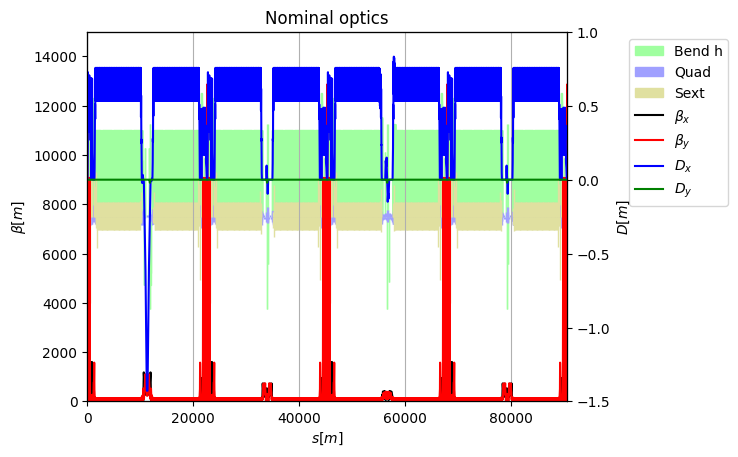

In [7]:
p = tw_nominal.plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Nominal optics');

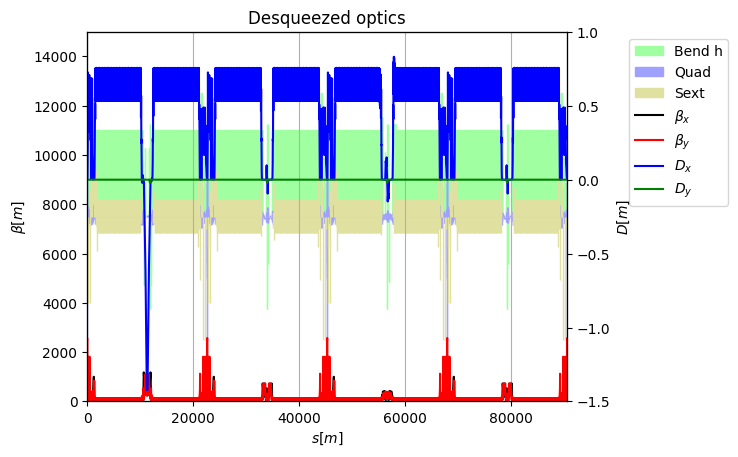

In [8]:
p = tw_desqueezed.plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Desqueezed optics');

### One experimental straight and neighbouring arcs

Compare the optics around `ipd`, including the dispersion suppressors and 500 m of arc on each side. Keep the same vertical scales as above.

In [9]:
s_start = tw_nominal['s', 'end_arc_start_ds_ipd'] - 500
s_end = tw_nominal['s', 'end_ds_start_arc_ipd'] + 500

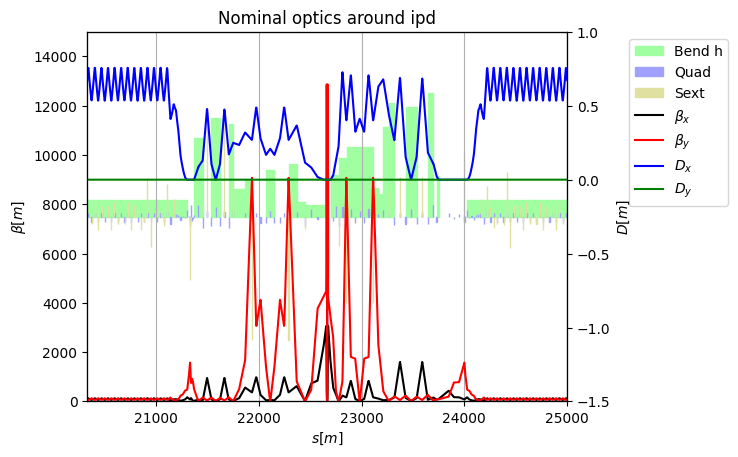

In [10]:
p = tw_nominal.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Nominal optics around ipd');

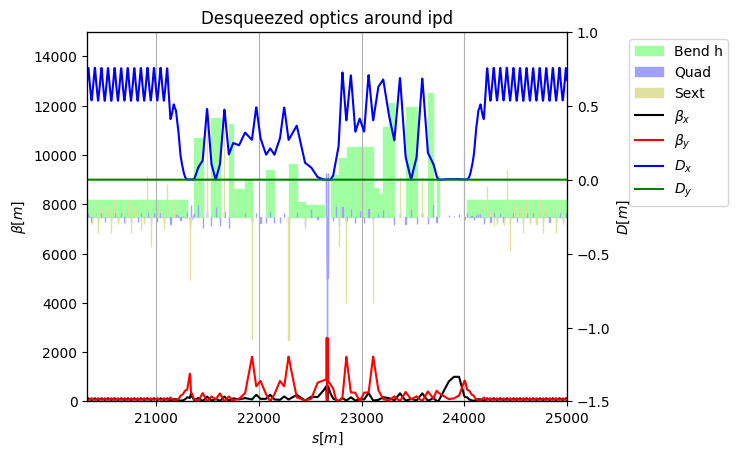

In [11]:
p = tw_desqueezed.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Desqueezed optics around ipd');

### Final doublets and neighbouring quadrupoles

Zoom into the region within 100 m of `ipd` on each side. Compare the nominal and desqueezed beta functions using the same vertical scales.

In [12]:
s_start = tw_nominal['s', 'ipd'] - 100
s_end = tw_nominal['s', 'ipd'] + 100

In [ ]:
p = tw_nominal.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Nominal final doublets and neighbouring quads');

In [ ]:
p = tw_desqueezed.rows[s_start:s_end:'s'].plot()
p.left.set_ylim(0, 15000)
p.right.set_ylim(-1.5, 1)
p.left.set_title('Desqueezed final doublets and neighbouring quads');